# **Clustering | Assignment (DA-AG-017)**

# **THEORY QUESTION**

### **1. What is the difference between K-Means and Hierarchical Clustering? Provide a use case for each.**

**Answer**:

| Aspect | K-Means | Hierarchical Clustering |
|---|---|---|
| **Approach** | Partitional. Starts with K random centroids, assigns each point to the nearest centroid, recomputes centroids, repeats until stable. | Builds a tree (dendrogram). **Agglomerative** (bottom-up) merges the closest clusters step by step; **divisive** (top-down) splits clusters. |
| **Number of clusters** | Must be given in advance (K). | Not needed in advance; choose by cutting the dendrogram at a level. |
| **Cluster shape** | Works best for spherical, similar-sized clusters. | Can capture nested structure; depends on linkage (single, complete, average, ward). |
| **Speed / size** | Fast and scalable, O(n·K·i). Good for large data. | Slow, O(n²) memory and time at least. Good for small to medium data. |
| **Result** | Different runs can give different results (random init). | Deterministic for a given linkage and metric. |
| **Interpretability** | Centroids are easy to interpret. | Dendrogram shows relationships at every level. |

🔹 **Use case, K-Means**: Customer segmentation of lakhs of e-commerce customers into 4 to 5 groups by spend and frequency, for targeted promotions.

🔹 **Use case, Hierarchical**: Grouping genes or species by similarity (taxonomy), or organising a few hundred products/documents into a category hierarchy, where the tree of relationships is useful.

### **2. Explain the purpose of the Silhouette Score in evaluating clustering algorithms.**

**Answer**:

The **Silhouette Score** measures how well each point fits in its own cluster compared with other clusters, so it tells us the quality of a clustering **without needing true labels**.

For a point `i`: `s(i) = (b - a) / max(a, b)`

* `a` = average distance of `i` to the other points in its **own** cluster (cohesion)
* `b` = average distance of `i` to the points in the **nearest other** cluster (separation)

🔹 **Range**: -1 to +1

* **Close to +1**: well matched to its own cluster and far from the others (good clustering)
* **Around 0**: point lies on the border between two clusters
* **Negative**: point is probably assigned to the wrong cluster

🔹 **Purpose / uses**: compare different algorithms (K-Means vs DBSCAN), choose the best number of clusters K (the K with the highest average silhouette), and find poorly formed clusters using the silhouette plot. *Limitation*: it favours compact, convex clusters, so it can under-rate density-based clusters such as moons.

In [1]:
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

X, _ = make_blobs(n_samples=300, centers=4, random_state=42)
for k in range(2, 8):
    labels = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X)
    print(f"k={k}  silhouette score = {silhouette_score(X, labels):.3f}")

k=2  silhouette score = 0.590
k=3  silhouette score = 0.757
k=4  silhouette score = 0.792
k=5  silhouette score = 0.689
k=6  silhouette score = 0.551
k=7  silhouette score = 0.430


### **3. What are the core parameters of DBSCAN, and how do they influence the clustering process?**

**Answer**:

DBSCAN (Density-Based Spatial Clustering of Applications with Noise) has two core parameters:

**1. `eps` (ε)**: the radius of the neighbourhood around a point.
* Too small: most points become noise and clusters break into many small pieces.
* Too large: separate clusters merge into one big cluster.

**2. `min_samples` (MinPts)**: the minimum number of points (including the point itself) needed inside `eps` for a point to be a **core point**.
* Larger value: stricter, more noise points, only dense regions become clusters (good for noisy data).
* Smaller value: more, smaller clusters and fewer outliers.

🔹 **Types of points**: **Core** (at least `min_samples` neighbours within `eps`), **Border** (inside the `eps` of a core point but not core itself), **Noise** (neither, label `-1`).

🔹 **Process**: pick an unvisited point → if it is a core point, start a cluster and keep adding all density-reachable points → otherwise mark as noise (it may later become a border point).

🔹 **Choosing values**: a common rule is `min_samples ≥ dimensions + 1` (often 2 × dimensions), and `eps` from the "knee" of the **k-distance graph**. DBSCAN also depends on the distance metric (`metric`, default Euclidean).

In [2]:
from sklearn.datasets import make_moons
from sklearn.cluster import DBSCAN

X, _ = make_moons(n_samples=200, noise=0.1, random_state=42)
for eps in [0.1, 0.15, 0.25, 0.4]:
    labels = DBSCAN(eps=eps, min_samples=8).fit_predict(X)
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    print(f"eps={eps:<4} -> clusters = {n_clusters}, noise points = {(labels == -1).sum()}")

eps=0.1  -> clusters = 2, noise points = 183
eps=0.15 -> clusters = 9, noise points = 82
eps=0.25 -> clusters = 2, noise points = 6
eps=0.4  -> clusters = 1, noise points = 0


### **4. Why is feature scaling important when applying clustering algorithms like K-Means and DBSCAN?**

**Answer**:

K-Means and DBSCAN are **distance-based** algorithms (they use Euclidean distance). If features are on different scales, the feature with the **largest range dominates** the distance and the others are almost ignored.

*Example*: Annual income (in thousands or lakhs) and age (20 to 60). Without scaling, a difference of 10,000 in income hides a difference of 20 years in age, so clusters are formed almost only by income.

🔹 **Effects of not scaling**
* **K-Means**: centroids and clusters are biased towards large-scale features, giving misleading segments.
* **DBSCAN**: a single `eps` cannot suit all features, so it gives too many noise points or merges clusters wrongly.
* Poor silhouette scores and unstable results.

🔹 **Solution**: use **StandardScaler** (mean 0, std 1) or **MinMaxScaler** (0 to 1) before clustering, so every feature contributes equally. Scaling should be done on numeric features; categorical features should be encoded first.

In [3]:
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

data = load_wine()
X, y = data.data, data.target
Xs = StandardScaler().fit_transform(X)

for name, M in [("Without scaling", X), ("With StandardScaler", Xs)]:
    labels = KMeans(n_clusters=3, random_state=42, n_init=10).fit_predict(M)
    print(f"{name:<22} agreement with true wine classes (ARI) = {adjusted_rand_score(y, labels):.3f}")

Without scaling        agreement with true wine classes (ARI) = 0.371
With StandardScaler    agreement with true wine classes (ARI) = 0.897


### **5. What is the Elbow Method in K-Means clustering and how does it help determine the optimal number of clusters?**

**Answer**:

The **Elbow Method** is a technique to choose the number of clusters K for K-Means.

🔹 **Idea**: Run K-Means for K = 1, 2, 3, ... and calculate the **WCSS / inertia** (Within-Cluster Sum of Squares, i.e. the sum of squared distances of points to their cluster centroid) for each K. Then plot K (x-axis) against WCSS (y-axis).

🔹 **Reading the plot**: WCSS always decreases as K increases (K = n gives 0). At first the drop is sharp, then it becomes slow. The point where the curve bends like an **elbow** is the optimal K, because adding more clusters after that gives only a small improvement.

🔹 **Limitations**: the elbow is sometimes not clear, so it is best combined with the **Silhouette Score** or the Gap statistic and with business knowledge.

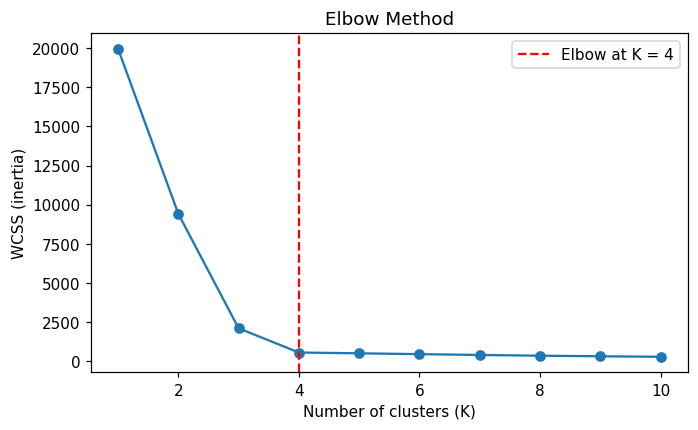

In [4]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans

X, _ = make_blobs(n_samples=300, centers=4, random_state=42)
wcss = [KMeans(n_clusters=k, random_state=42, n_init=10).fit(X).inertia_ for k in range(1, 11)]

plt.figure(figsize=(7, 4))
plt.plot(range(1, 11), wcss, "o-")
plt.axvline(4, color="red", linestyle="--", label="Elbow at K = 4")
plt.xlabel("Number of clusters (K)"); plt.ylabel("WCSS (inertia)")
plt.title("Elbow Method"); plt.legend(); plt.show()

# **PRACTICAL QUESTIONS**

### **6. Generate synthetic data using make_blobs(n_samples=300, centers=4), apply KMeans clustering, and visualize the results with cluster centers.**

**Answer**:

Cluster centers:
 [[-2.71  8.97]
 [-6.83 -6.83]
 [ 4.72  2.04]
 [-8.87  7.17]]
Points per cluster: [76, 75, 75, 74]
Inertia (WCSS): 564.91


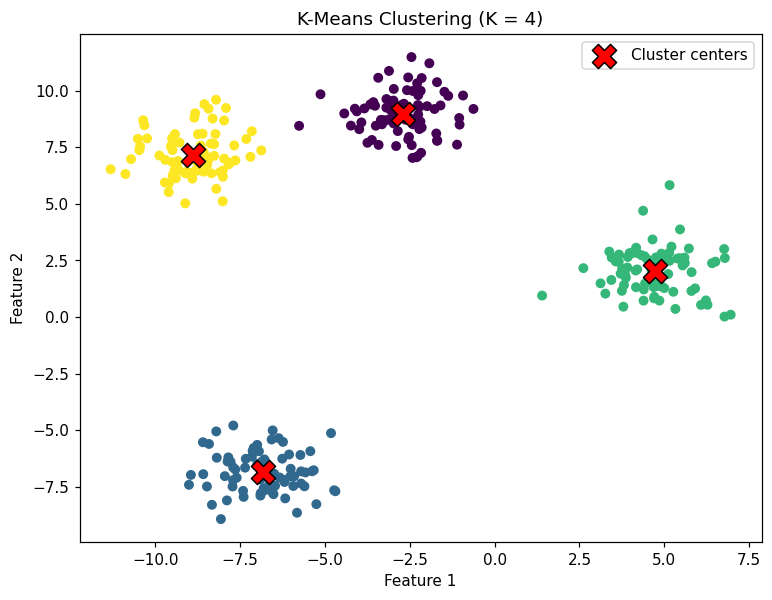

In [5]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans

# 1. Generate data
X, y_true = make_blobs(n_samples=300, centers=4, random_state=42)

# 2. Apply KMeans
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
labels = kmeans.fit_predict(X)
centers = kmeans.cluster_centers_

print("Cluster centers:\n", centers.round(2))
print("Points per cluster:", [int((labels == i).sum()) for i in range(4)])
print("Inertia (WCSS):", round(kmeans.inertia_, 2))

# 3. Visualize clusters and centers
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], c=labels, cmap="viridis", s=30)
plt.scatter(centers[:, 0], centers[:, 1], c="red", marker="X", s=250,
            edgecolors="black", label="Cluster centers")
plt.title("K-Means Clustering (K = 4)")
plt.xlabel("Feature 1"); plt.ylabel("Feature 2"); plt.legend(); plt.show()

**Interpretation**: K-Means separates the 4 blobs cleanly; the red X marks are the centroids of each cluster.

### **7. Load the Wine dataset, apply StandardScaler, and then train a DBSCAN model. Print the number of clusters found (excluding noise).**

**Answer**:

In [6]:
import numpy as np
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN

# 1. Load and scale
X = load_wine().data
X_scaled = StandardScaler().fit_transform(X)

# 2. DBSCAN (eps chosen from k-distance values; 13 features so a larger eps is needed)
db = DBSCAN(eps=2.5, min_samples=10)
labels = db.fit_predict(X_scaled)

# 3. Number of clusters excluding noise (label -1)
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = int(np.sum(labels == -1))

print("Number of clusters found (excluding noise):", n_clusters)
print("Number of noise points:", n_noise)
values, counts = np.unique(labels, return_counts=True)
print("Cluster label counts (-1 = noise):", {int(v): int(c) for v, c in zip(values, counts)})

Number of clusters found (excluding noise): 2
Number of noise points: 32
Cluster label counts (-1 = noise): {-1: 32, 0: 101, 1: 45}


**Interpretation**: DBSCAN finds **2 dense clusters** and marks the remaining points as noise (`-1`). The Wine data has 13 features and its 3 classes overlap in density, so DBSCAN does not recover exactly 3 groups; the result depends strongly on `eps` and `min_samples`.

### **8. Generate moon-shaped synthetic data using make_moons(n_samples=200, noise=0.1), apply DBSCAN, and highlight the outliers in the plot.**

**Answer**:

Clusters found: 2
Outliers (noise points): 6


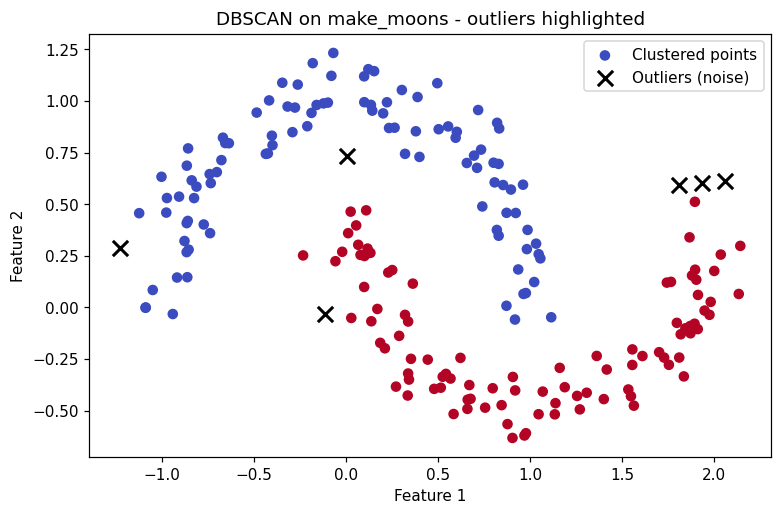

In [7]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.cluster import DBSCAN

# 1. Generate moon-shaped data
X, _ = make_moons(n_samples=200, noise=0.1, random_state=42)

# 2. Apply DBSCAN
labels = DBSCAN(eps=0.25, min_samples=8).fit_predict(X)
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
print("Clusters found:", n_clusters)
print("Outliers (noise points):", int((labels == -1).sum()))

# 3. Plot clusters and highlight outliers
plt.figure(figsize=(8, 5))
core = labels != -1
plt.scatter(X[core, 0], X[core, 1], c=labels[core], cmap="coolwarm", s=35, label="Clustered points")
plt.scatter(X[~core, 0], X[~core, 1], c="black", marker="x", s=100, linewidths=2, label="Outliers (noise)")
plt.title("DBSCAN on make_moons - outliers highlighted")
plt.xlabel("Feature 1"); plt.ylabel("Feature 2"); plt.legend(); plt.show()

**Interpretation**: Unlike K-Means, DBSCAN correctly follows the two curved moon shapes, and the few points far from dense regions are marked as outliers (black crosses).

### **9. Load the Wine dataset, reduce it to 2D using PCA, then apply Agglomerative Clustering and visualize the result in 2D with a scatter plot.**

**Answer**:

Explained variance ratio: [0.362 0.192] | total = 0.554
Points per cluster: [69, 48, 61]
Agreement with true wine classes (ARI): 0.896


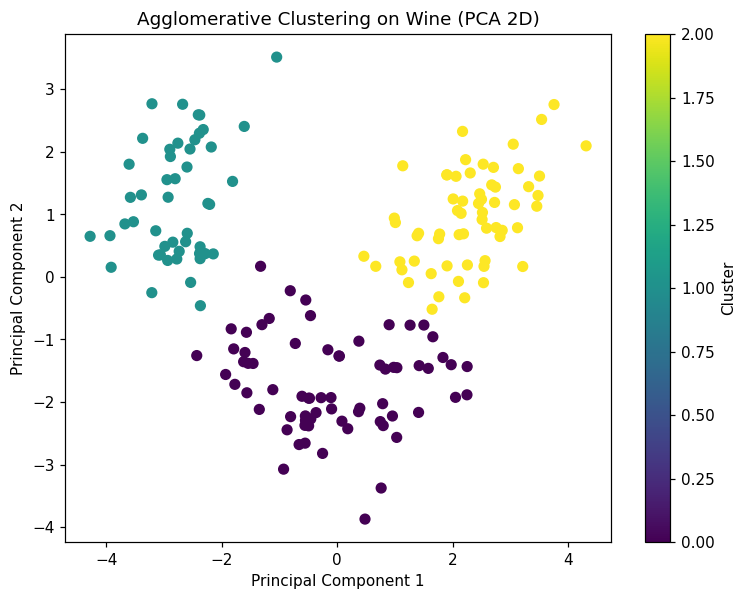

In [8]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import adjusted_rand_score

# 1. Load, scale, and reduce to 2D with PCA
wine = load_wine()
X = wine.data
X_scaled = StandardScaler().fit_transform(X)
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
print("Explained variance ratio:", pca.explained_variance_ratio_.round(3),
      "| total =", round(pca.explained_variance_ratio_.sum(), 3))

# 2. Agglomerative Clustering (Ward linkage)
agg = AgglomerativeClustering(n_clusters=3, linkage="ward")
labels = agg.fit_predict(X_pca)
print("Points per cluster:", [int((labels == i).sum()) for i in range(3)])
print("Agreement with true wine classes (ARI):", round(adjusted_rand_score(wine.target, labels), 3))

# 3. Visualize
plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=labels, cmap="viridis", s=40)
plt.title("Agglomerative Clustering on Wine (PCA 2D)")
plt.xlabel("Principal Component 1"); plt.ylabel("Principal Component 2")
plt.colorbar(label="Cluster"); plt.show()

**Interpretation**: The first two principal components keep about 55% of the variance, and Agglomerative Clustering with Ward linkage forms 3 well separated groups in the 2D space, matching the 3 real wine types very well (ARI about 0.90).

### **10. Real-world workflow: customer segmentation for an e-commerce company using clustering**

**Answer**:

🔹 **1. Which clustering algorithm(s) and why?**
* **K-Means** as the main algorithm: customer data is large, numeric after scaling, and K-Means is fast and gives easy-to-explain centroids (e.g. "high spenders, bargain hunters").
* **Hierarchical (Agglomerative)** on a sample to view the dendrogram and cross-check the number of segments.
* **DBSCAN** to find unusual customers (very high spenders or bots) as outliers, which should be handled separately so they do not distort the segments.

🔹 **2. Preprocessing**
* **Missing values**: median for numeric columns (age, income), most frequent for categorical; drop rows or columns with too many missing values.
* **Outliers**: cap using IQR/percentiles, or check with DBSCAN.
* **Features**: build behaviour features such as total spend, number of orders, recency, average order value, and spend per category (electronics, fashion, grocery, beauty). Encode categorical demographics with one-hot encoding.
* **Scaling**: **StandardScaler**, because K-Means uses distances.
* Optionally reduce with PCA for visualization.

🔹 **3. Number of clusters**: Use the **Elbow Method** (WCSS) and the **Silhouette Score** together for K = 2 to 10, then pick K that is both statistically good and meaningful for marketing (not too many segments to act on).

🔹 **4. Benefits to marketing**
* **Targeted promotions** per segment (discounts for price-sensitive customers, early access for loyal high spenders).
* **Win-back campaigns** for customers with high recency (inactive).
* **Cross-sell** the categories that each segment already prefers.
* Better budget allocation, higher conversion and retention, and lower campaign cost. Segments can be refreshed monthly and tracked on a dashboard.

*(The code below uses simulated customer data. Replace the data creation step with `pd.read_csv("customers.csv")` for the real dataset.)*

Missing values before cleaning:
 age         25
income_k    25
dtype: int64
Silhouette scores: {2: 0.549, 3: 0.532, 4: 0.577, 5: 0.502, 6: 0.419, 7: 0.365, 8: 0.367}
Best K by silhouette: 4

Customers per segment:
 segment
0    212
1    150
2     80
3    158
Name: count, dtype: int64

Segment profile (mean values):
           age  income_k  orders  electronics  fashion  grocery  beauty  total_spend
segment                                                                            
0        24.0      30.0    12.0         50.0    304.0     80.0   118.0        552.0
1        38.0      71.0    20.0        406.0    146.0    252.0    78.0        882.0
2        35.0     125.0    30.0        899.0    505.0    295.0   242.0       1942.0
3        45.0      53.0    40.0         58.0     89.0    609.0    69.0        826.0


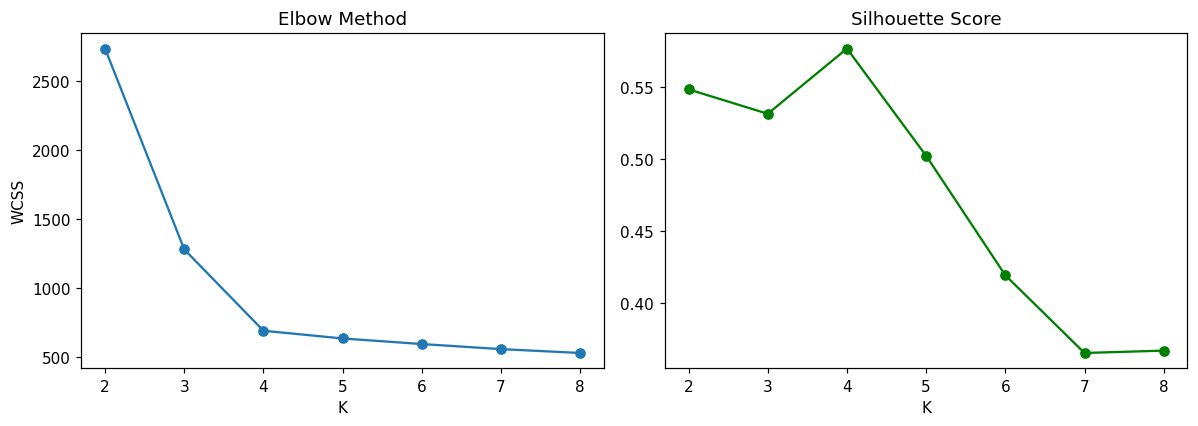

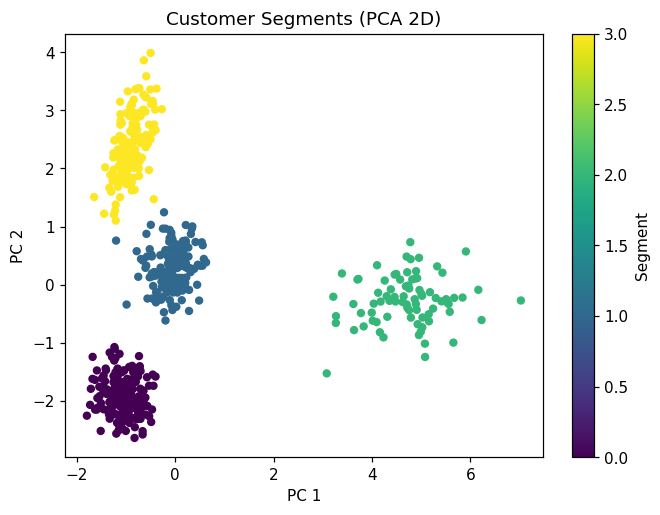

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

# ---------- 1. Simulated customer data (replace with real CSV) ----------
rng = np.random.default_rng(42)
n = 600
seg = rng.choice(4, n, p=[0.35, 0.25, 0.25, 0.15])
base = np.array([  # age, income, orders, electronics, fashion, grocery, beauty
    [24, 30, 12,  50, 300,  80, 120],   # young fashion / beauty buyers
    [38, 70, 20, 400, 150, 250,  80],   # mid-age electronics buyers
    [45, 55, 40,  60,  90, 600,  70],   # frequent grocery shoppers
    [35, 120, 30, 900, 500, 300, 250],  # high-value premium customers
], dtype=float)
cols = ["age", "income_k", "orders", "electronics", "fashion", "grocery", "beauty"]
df = pd.DataFrame(base[seg] * rng.normal(1, 0.18, (n, 7)), columns=cols)
df["total_spend"] = df[["electronics", "fashion", "grocery", "beauty"]].sum(axis=1)

# add some missing values like real data
for c in ["age", "income_k"]:
    df.loc[rng.choice(n, 25, replace=False), c] = np.nan
print("Missing values before cleaning:\n", df.isna().sum()[df.isna().sum() > 0])

# ---------- 2. Preprocess: impute + scale ----------
X = SimpleImputer(strategy="median").fit_transform(df)
X_scaled = StandardScaler().fit_transform(X)

# ---------- 3. Choose K: Elbow + Silhouette ----------
ks = range(2, 9)
wcss, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_scaled)
    wcss.append(km.inertia_); sil.append(silhouette_score(X_scaled, km.labels_))
best_k = list(ks)[int(np.argmax(sil))]
print("Silhouette scores:", {k: round(float(v), 3) for k, v in zip(ks, sil)})
print("Best K by silhouette:", best_k)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(ks, wcss, "o-"); ax[0].set_title("Elbow Method"); ax[0].set_xlabel("K"); ax[0].set_ylabel("WCSS")
ax[1].plot(ks, sil, "o-", color="green"); ax[1].set_title("Silhouette Score"); ax[1].set_xlabel("K")
plt.tight_layout(); plt.show()

# ---------- 4. Final model + segment profile ----------
km = KMeans(n_clusters=best_k, random_state=42, n_init=10).fit(X_scaled)
df["segment"] = km.labels_
print("\nCustomers per segment:\n", df["segment"].value_counts().sort_index())
pd.set_option("display.width", 200); pd.set_option("display.max_columns", None)
print("\nSegment profile (mean values):\n", df.groupby("segment").mean().round(0))

# ---------- 5. Visualize segments in 2D ----------
p = PCA(n_components=2).fit_transform(X_scaled)
plt.figure(figsize=(7, 5))
plt.scatter(p[:, 0], p[:, 1], c=df["segment"], cmap="viridis", s=20)
plt.title("Customer Segments (PCA 2D)"); plt.xlabel("PC 1"); plt.ylabel("PC 2")
plt.colorbar(label="Segment"); plt.show()